In [1]:
#!pip install pandas

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
import warnings

# Suppress all warnings
warnings.filterwarnings("ignore")

#Load the file to read: parameters.csv

In [4]:
#Let us open to browse the file
from google.colab import files
uploaded= files.upload()

Saving parameters.csv to parameters.csv


In [5]:
#/content/parameters
FILENAME='/content/parameters.csv'

#df= pd.read_csv(FILENAME, encoding="latin1")  #utf-8
df= pd.read_csv(FILENAME, encoding="latin1")  #utf-8
#pd.read_excel
#UTF stands for "Unicode Transformation Format"
#'8' means that 8-bit values are used in the encoding.

#Data frame Information

In [6]:
#-----------------------Data frame Information--------------------------------
print("-----------df info-----------")
print(df.info())

# Column names
print("-----------df Column------------")
print(df.columns)
# Check the first 5 rows of the data frame# Check
print("-----------df head------------")
print(df.head())  #few top rows by using the function head()
                  #default top 5 rows
print() # blank line
print("-------------df first top 10 records-----------")
print(df.head(10)) #few top rows by using the function head(10) for top 10 rows

#tail
print("-------------df tail-----------")
print(df.tail()) #last five record



#optional
print("\nNumeric Columns")
numericdf= df.select_dtypes('number')
print(numericdf.columns)

print("\nNon-Numeric Columns")
objectdf= df.select_dtypes('object')
print(objectdf.columns)

print("\nAll")
print(df.columns)

-----------df info-----------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   flight      209 non-null    int64  
 1   speed       209 non-null    float64
 2   payload     209 non-null    float64
 3   altitude    209 non-null    object 
 4   date        209 non-null    object 
 5   local_time  209 non-null    object 
 6   route       209 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 11.6+ KB
None
-----------df Column------------
Index(['flight', 'speed', 'payload', 'altitude', 'date', 'local_time',
       'route'],
      dtype='object')
-----------df head------------
   flight  speed  payload altitude        date local_time route
0       1    4.0      0.0       25  2019-04-07      10:13    R5
1       2    4.0      0.0       50  2019-04-07      10:23    R5
2       3    6.0      0.0       25  2019-04-07      10:33    R5

# Descriptive Analytics

In [7]:
#df['column_name'].describe()
df[['speed','payload','altitude']].describe()

,speed,payload
count,209.000000,209.000000
mean,7.492823,235.645933
std,3.372855,211.813799
min,0.000000,0.000000
25%,4.000000,0.000000
50%,8.000000,250.000000
75%,10.000000,500.000000
max,12.000000,750.000000


In [8]:
df.describe()

,flight,speed,payload
count,209.000000,209.000000,209.000000
mean,161.339713,7.492823,235.645933
std,72.211591,3.372855,211.813799
min,1.000000,0.000000,0.000000
25%,112.000000,4.000000,0.000000
50%,167.000000,8.000000,250.000000
75%,219.000000,10.000000,500.000000
max,279.000000,12.000000,750.000000


In [9]:
df.describe().loc[['mean', '50%', 'min', 'max', 'std']]

,flight,speed,payload
mean,161.339713,7.492823,235.645933
50%,167.000000,8.000000,250.000000
min,1.000000,0.000000,0.000000
max,279.000000,12.000000,750.000000
std,72.211591,3.372855,211.813799


In [10]:
df

,flight,speed,payload,altitude,date,local_time,route
0,1,4.0,0.0,25,2019-04-07,10:13,R5
1,2,4.0,0.0,50,2019-04-07,10:23,R5
2,3,6.0,0.0,25,2019-04-07,10:33,R5
3,4,8.0,0.0,25,2019-04-07,10:48,R5
4,5,4.0,0.0,25,2019-04-07,11:05,R2
...,...,...,...,...,...,...,...
204,275,8.0,500.0,25,2019-10-24,9:05,R1
205,276,10.0,500.0,25,2019-10-24,9:32,R1
206,277,10.0,500.0,25,2019-10-24,9:45,R1
207,278,10.0,500.0,25-50-100-25,2019-10-24,10:00,R7


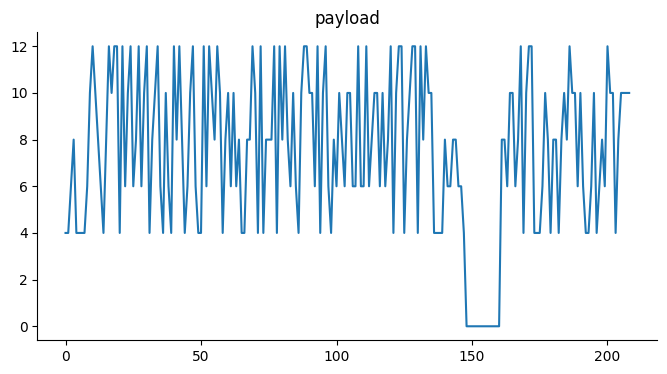

In [11]:
from matplotlib import pyplot as plt
df['speed'].plot(kind='line', figsize=(8, 4), title='payload')
plt.gca().spines[['top', 'right']].set_visible(False)

In [12]:
df.max(numeric_only=True)

,0
flight,279.0
speed,12.0
payload,750.0


#Heat map using seaborn

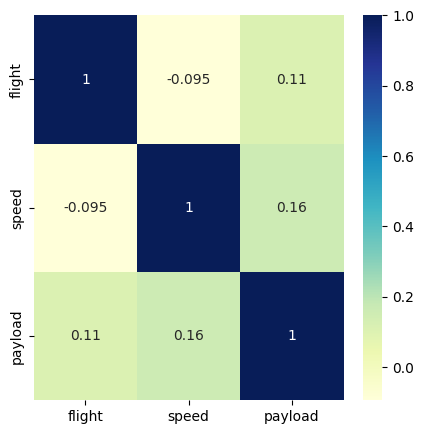

In [13]:
import seaborn as sn
# plotting correlation heatmap
figure = plt.figure(figsize=(5,5))
dataplot=sn.heatmap(df.corr(numeric_only=True),  cmap="YlGnBu", annot=True)

#displaying heatmap
#plt.show()

#Try another color for the heatmap!

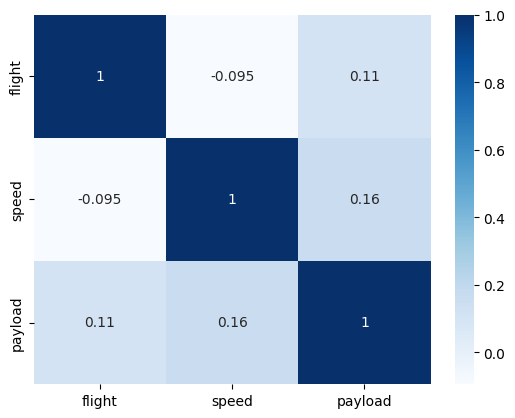

In [14]:
import seaborn as sn
# plotting correlation heatmap
#https://medium.com/@morganjonesartist/color-guide-to-seaborn-palettes-da849406d44f
#cmap="Blues"
#cmap="BuPu"
# cmap="Greens"
#cmap="coolwarm"
#cmap="Reds"
#cmap="winter"
#cmap="rocket_r"
numeric_df = df.select_dtypes(include='number')
dataplot=sn.heatmap(numeric_df.corr(),  cmap="Blues", annot=True)
#displaying heatmap
#plt.show()

#Histogram Visualization

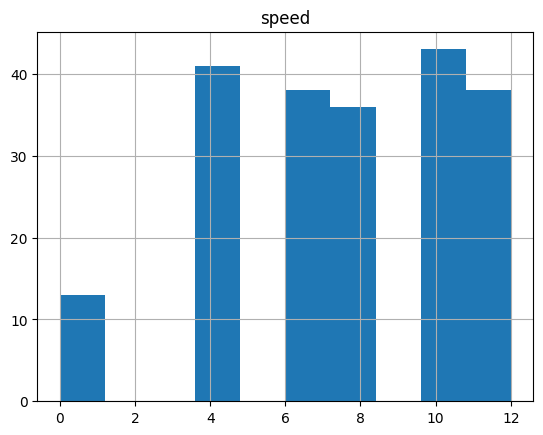

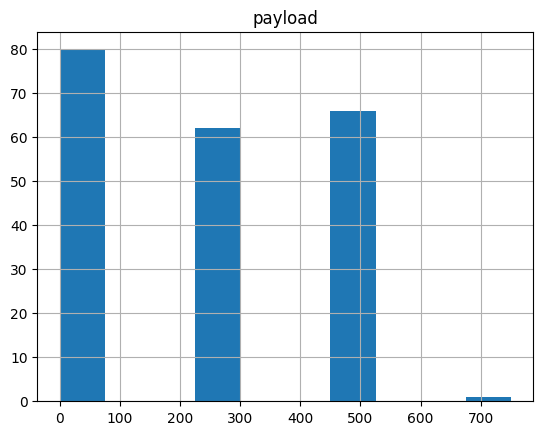

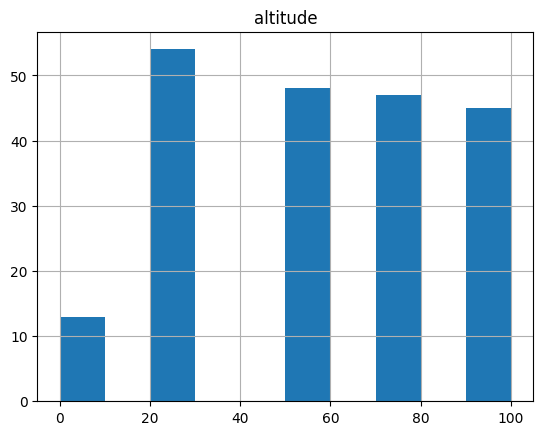

In [15]:
#Histogram Visualization
#Draw by hand or with an application program a histogram for the ‘rating’ variables.
df['altitude'] = pd.to_numeric(df['altitude'], errors = 'coerce')
df.hist(column='speed')  # default bin size
df.hist(column='payload')  # default bin size
df.hist(column='altitude')  # default bin size
#plt.xlabel("Values for Market Value")
#plt.ylabel("Frequencies")
plt.show()

#Box plots

In [16]:
df.columns

Index(['flight', 'speed', 'payload', 'altitude', 'date', 'local_time',
       'route'],
      dtype='object')

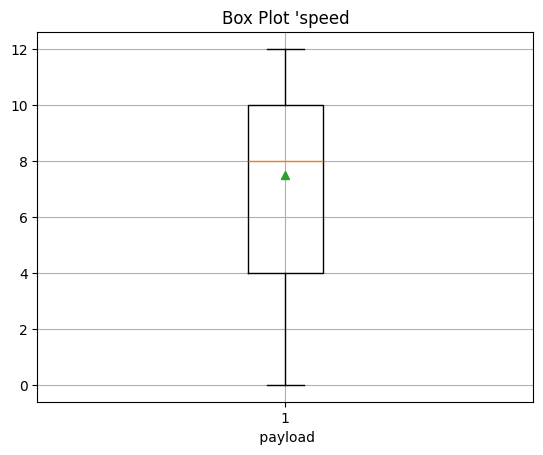

In [17]:
plt.boxplot(df['speed'], showmeans=True)
plt.xlabel(' payload')
plt.title("Box Plot 'speed")
plt.grid(True)
plt.show()

<Axes: >

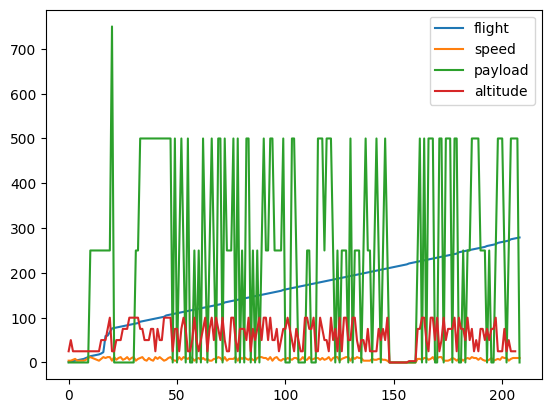

In [18]:
df.plot()

In [19]:
df.columns

Index(['flight', 'speed', 'payload', 'altitude', 'date', 'local_time',
       'route'],
      dtype='object')

In [20]:
# Define independent variables (X) and dependent variable (y)
X = df[['payload', 'altitude']]
y = df['speed']

# In the above code, the first colon(:) is used to take all the rows, and
# the second colon(:) is for all the columns.
# Here we have used :-1 from the right slicing,
# because we don't want the last column as it contains the dependent variable.
print("-------------x--- Payload', 'Altitude ------")
print(X)
print("-------------Y--- Speed ------")
print(y)

-------------x--- Payload', 'Altitude ------
     payload  altitude
0        0.0      25.0
1        0.0      50.0
2        0.0      25.0
3        0.0      25.0
4        0.0      25.0
..       ...       ...
204    500.0      25.0
205    500.0      25.0
206    500.0      25.0
207    500.0       NaN
208      0.0       NaN

[209 rows x 2 columns]
-------------Y--- Speed ------
0       4.0
1       4.0
2       6.0
3       8.0
4       4.0
       ... 
204     8.0
205    10.0
206    10.0
207    10.0
208    10.0
Name: speed, Length: 209, dtype: float64


In [21]:
import seaborn as sns

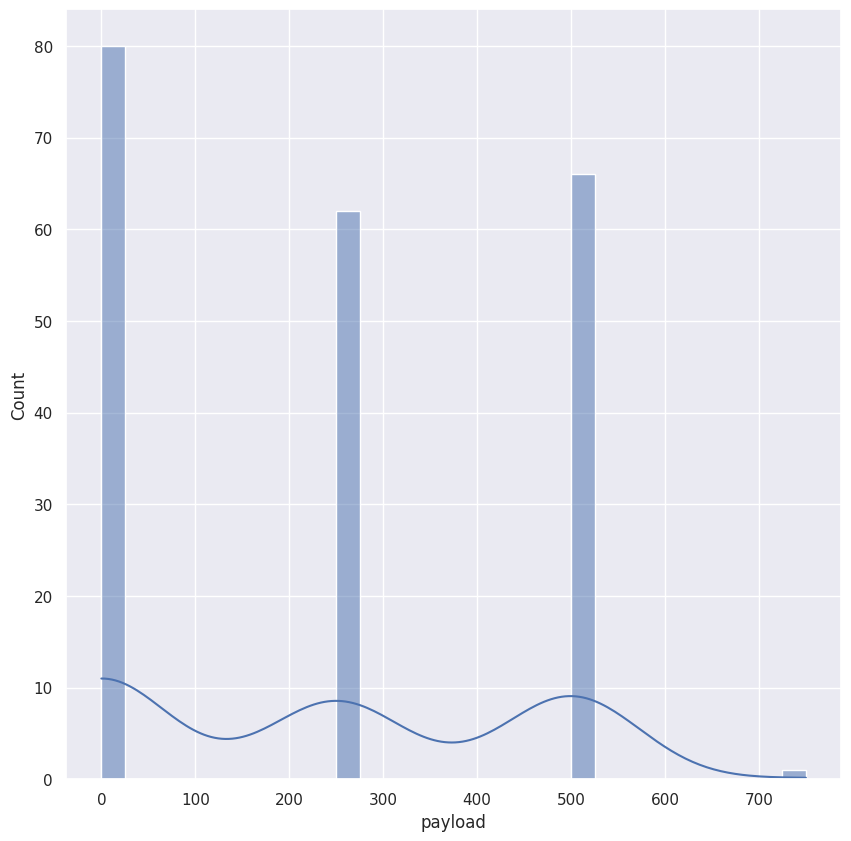

In [22]:
sns.set(rc={'figure.figsize':(10,10)})
sns.histplot(df['payload'], bins=30, kde=True)
plt.show()

#skewness from histogram for the Target Y

In [23]:
#pip install scipy
from scipy.stats import skew
#check some variables skewnewss values
print('\nSkewness for data variable: ', skew(df['speed']))


Skewness for data variable:  -0.39945754061356853


skewness >0 more weight in the left tail of the distribution

#Check Any missing Values!
#Strategies to handles

In [24]:
# Let us check summary for missing values----------Check for any missing values
# Total missing values for each feature
print("\nAny Null!-------------------------")
print(df.isnull().any())
print("\n")

#or
#df.isna().sum()

#or
 #show all rows with NaN values for entire dataframe
# df[df.isnull().any(axis=1)]


print("Summarizing Missing Values")
print(df.isnull().sum())

#print(df.isna().any())
#print(df.isna().sum())
#-------------------------------------------------------------


Any Null!-------------------------
flight        False
speed         False
payload       False
altitude       True
date          False
local_time    False
route         False
dtype: bool


Summarizing Missing Values
flight        0
speed         0
payload       0
altitude      2
date          0
local_time    0
route         0
dtype: int64


In [25]:
### drop null values
# df = df.dropna()

### replace by mean
#df['Salary'].fillna(df['Salary'].mean(),inplace=True)

####--------------------------------------------------------
### Replace null values with 'No value' for string and average for numeric.
####--------------------------------------------------------
#   df = df.apply(lambda x: x.fillna(x.mean()) if x.dtype.kind in ['i','f'] else x.fillna('No Value'))


#or
#replace null value under College with 'Unknown' and Salary with mean value
#df_result = df.fillna(value={'College':'Unknown', 'Salary': round(df['Salary'].mean())})

#and Salary with medain value
#df_result = df.fillna(value={'College':'Unknown', 'Salary': round(df['Salary'].median())})

#Imputation for missing data


If "mean", then replace missing values using the mean along each column. Can only be used with numeric data.

If "median", then replace missing values using the median along each column. Can only be used with numeric data.

If "most_frequent", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.

If "constant", then replace missing values with fill_value. Can be used with strings or numeric data.

In [26]:
import numpy as np
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy='mean')
print(type(imputer))
newdf= df.select_dtypes('number')
imputed=pd.DataFrame(imputer.fit_transform(newdf),columns=newdf.columns)
print(imputed.head())

print(imputed.isnull().sum(axis=0))

<class 'sklearn.impute._base.SimpleImputer'>
   flight  speed  payload  altitude
0     1.0    4.0      0.0      25.0
1     2.0    4.0      0.0      50.0
2     3.0    6.0      0.0      25.0
3     4.0    8.0      0.0      25.0
4     5.0    4.0      0.0      25.0
flight      0
speed       0
payload     0
altitude    0
dtype: int64


#Step-1: Spliting Data: Train and Test

In [27]:
# Splitting the dataset into training and test set.

#train_test_split() function:
#our parameters in which first two are for arrays of data,
#test_size is for specifying the size of the test set.
#The test_size maybe .5, .3, or .2, which tells the dividing ratio of training and testing sets.
#random_state is used to set a seed for a random generator so that you always get the same result,
# used random =5
X = imputed.drop(columns=['payload'])
y = imputed['payload']
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size= 1/3,
                                                    random_state=5)

print("\nX_train", x_train)
print("\n")
print("x_test", x_test )
print("\n")
print("y_train", y_train )
print("\n")
print("y_test", y_test )

print("\nx_train", x_train.shape,
      "\nx_test",x_test.shape,
      "\ny_train",y_train.shape,
      "\ny_test",y_test.shape)

# better to use size too
print("\nx_train", x_train.size,
      "\nx_test",x_test.size,
      "\ny_train",y_train.size,
      "\ny_test",y_test.size)


X_train      flight  speed  altitude
59    119.0    8.0      50.0
89    151.0   12.0      50.0
12     16.0    8.0      25.0
71    131.0    4.0     100.0
186   252.0   12.0      75.0
..      ...    ...       ...
144   207.0    8.0      50.0
118   181.0    6.0      50.0
189   255.0    6.0      25.0
206   277.0   10.0      25.0
99    162.0    8.0      75.0

[139 rows x 3 columns]


x_test      flight  speed  altitude
21     77.0   12.0      25.0
53    113.0   12.0     100.0
120   183.0   12.0      25.0
51    111.0   12.0      25.0
26     82.0    8.0      75.0
..      ...    ...       ...
43    101.0    8.0      50.0
62    122.0   10.0      75.0
173   237.0    4.0     100.0
150   213.0    0.0       0.0
115   178.0   10.0      25.0

[70 rows x 3 columns]


y_train 59       0.0
89     250.0
12     250.0
71       0.0
186    500.0
       ...  
144      0.0
118    250.0
189    500.0
206    500.0
99     500.0
Name: payload, Length: 139, dtype: float64


y_test 21       0.0
53     250.0
120    5

#Step-2: Fitting the Simple Linear Regression to the Training Set

#Step-3: Prediction of test set result





In [28]:
#--------------------------------------------
#Step-2: Fitting the Simple Linear Regression to the Training Set:
#--------------------------------------------

#Fitting the Simple Linear Regression model to the training dataset

from sklearn.linear_model import LinearRegression
regressor= LinearRegression()
regressor.fit(x_train, y_train)
print(regressor)
#--------------------------------------------
#Step-3: Prediction of test set result:
#--------------------------------------------
#Prediction of Test and Training set result
y_pred= regressor.predict(x_test)
x_pred= regressor.predict(x_train)  # optional to visualization

print("\ny_pred",y_pred)
print("x_pred",x_pred)

#Step-4  visualizing the Training set results:
#--------------------------------------------



LinearRegression()

y_pred [203.57271155 255.65067022 230.38204592 212.17193201 231.29556144
 290.55581204 223.80859494 245.03052726 181.48774915 220.81652738
 254.23616518 229.94747194 223.71413185 269.05776089 264.41931067
 274.88342197 283.30468108 218.59177482 249.33625536 216.30454573
 267.45432966 274.12466722 248.59458332 287.09845481 234.50854178
 252.78507123 262.83538564 274.03020413 246.99115209 182.9193369
 236.01508643 232.66073365 225.73990132 261.56837091 252.28777609
 252.13301532 279.93936346 217.32718357 257.17672107 233.2500684
 212.2493124  266.27323667 232.89899268 210.99326251 208.88399478
 240.48411665 208.12766352 213.43652326 252.70769084 225.24018269
 259.20860841 218.65576687 233.57794355 219.92889947 236.18692991
 217.58010182 237.03530078 217.30767737 250.34181048 194.54745847
 285.15860707 244.37235348 221.57528213 285.74794182 271.61599727
 221.7767076  242.50746264 282.63184807 217.07426532 228.02228343]
x_pred [226.32923608 236.61296253 185.95435588 255

#Step-4  Model Statistics and score:

In [29]:
#--------------------------------------------
#Step-4  Model Statistics and score:
#--------------------------------------------

#Method #1
# our model is  y=a+b×x+ϵ  then the estimation of
# b coeff
# a is the estimation of the intercept
#--------------------------------------------
# >>>>>>>Print out the statistics<<<<<<<<<<<<<
print("R^2", regressor.score(x_train,y_train))
print("Model Coef",regressor.coef_)
print("Model Intercept",regressor.intercept_)
#--------------------------------------------

R^2 0.015958299423155298
Model Coef [0.25291825 0.54758562 0.57297202]
Model Intercept 163.20267833739803



    Predicted House Market  = 37553.12 + -348.55 * House Age + 38.22 * Square Feet

#Method 2 for LR
#Ordinary Least Squares regression (OLS)

In [30]:
#Method 2
#We will be using now statsmodels library.
#Ordinary Least Squares regression (OLS)
import statsmodels.api as sm
print("\n")
print(dir(sm))
print("\n")

#-------------The model without constant (intercept):y=b×x+ϵ
print("The model with constant (intercept):y=b×x+ϵ")
print(type(x_train))    #<class 'numpy.ndarray'>
# Add a constant to the independent variables (intercept term)
x_train = sm.add_constant(x_train)
model0 = sm.OLS(y_train, x_train).fit()
print(model0.summary())
print("\n")



['BayesGaussMI', 'BinomialBayesMixedGLM', 'ConditionalLogit', 'ConditionalMNLogit', 'ConditionalPoisson', 'Factor', 'GEE', 'GLM', 'GLMGam', 'GLS', 'GLSAR', 'GeneralizedPoisson', 'HurdleCountModel', 'Logit', 'MANOVA', 'MI', 'MICE', 'MICEData', 'MNLogit', 'MixedLM', 'NegativeBinomial', 'NegativeBinomialP', 'NominalGEE', 'OLS', 'OrdinalGEE', 'PCA', 'PHReg', 'Poisson', 'PoissonBayesMixedGLM', 'ProbPlot', 'Probit', 'QuantReg', 'RLM', 'RecursiveLS', 'SurvfuncRight', 'TruncatedLFNegativeBinomialP', 'TruncatedLFPoisson', 'WLS', 'ZeroInflatedGeneralizedPoisson', 'ZeroInflatedNegativeBinomialP', 'ZeroInflatedPoisson', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '__version__', '__version_info__', 'add_constant', 'categorical', 'cov_struct', 'datasets', 'distributions', 'duration', 'emplike', 'families', 'formula', 'gam', 'genmod', 'graphics', 'iolib', 'load', 'load_pickle', 'multivariate', 'nonparametric', 'qqline', 'qqplo


   Predicted House Market = 37553.12 + -348.55 * House Age + 38.22 * Square Feet

#seaborn jointplot

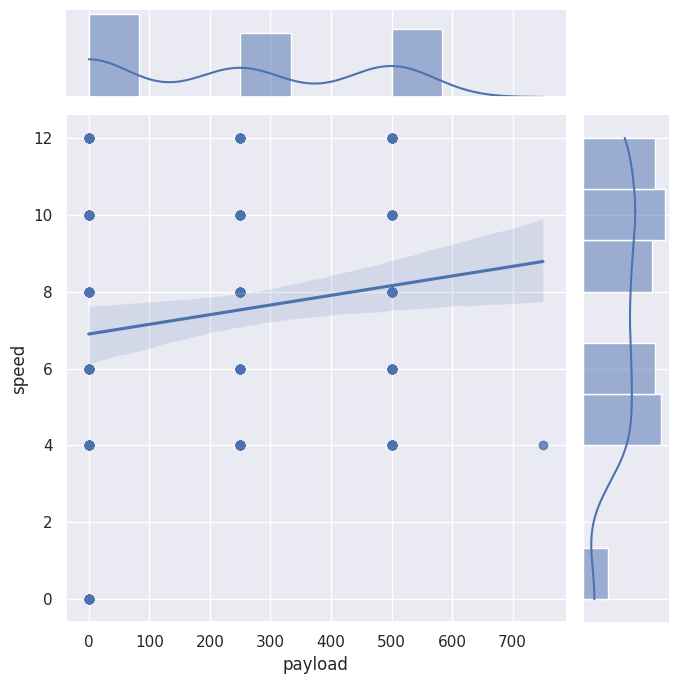

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.jointplot(x="payload",
              y="speed",
              data=df,
              kind = 'reg',
              fit_reg= True,
              height = 7)
plt.show()

#Three plots:

scatter

reg

density

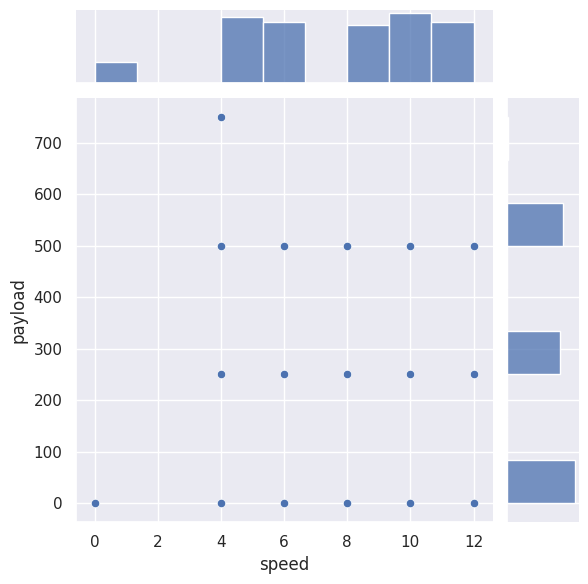

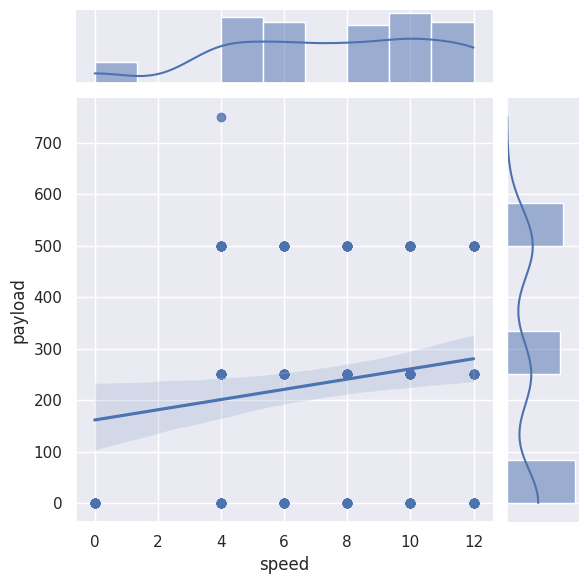

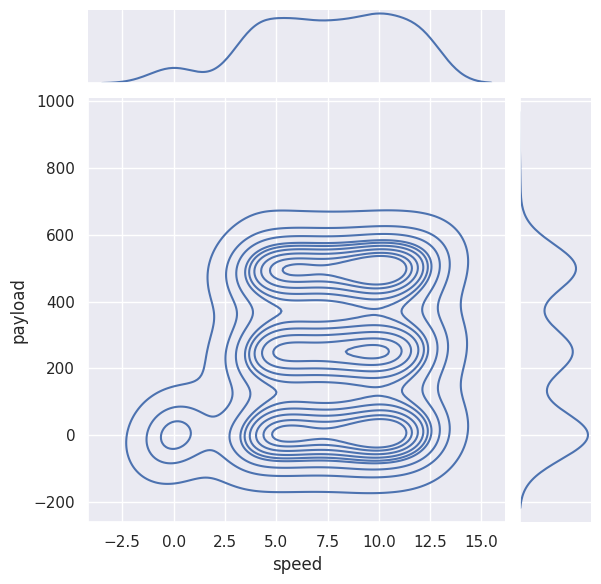

In [32]:
# try
sns.jointplot(x="speed", y="payload", data=df) # default kind='scatter'
plt.show()

sns.jointplot(x="speed", y="payload", data=df, kind='reg', fit_reg=True)
plt.show()

sns.jointplot(x="speed", y="payload", data=df, kind='kde') #density
plt.show()

In [33]:
#Predict the speed

# The model was trained on 'flight', 'speed', and 'altitude'.
# We need to provide values for all three when making a prediction.
# Using a placeholder for flight, and typical values from the dataset for speed and altitude.
# You can change the values as needed.
new_data = np.array([[0, 10, 4000]]).reshape(1, -1)
prediction = regressor.predict(new_data)
print(prediction)
print(f"Your predicted payload is {prediction[0]:,.2f}")

[2460.56662587]
Your predicted payload is 2,460.57


In [34]:
import statsmodels.api as sm
import pandas as pd

# Convert altitude to numeric
df['altitude'] = pd.to_numeric(df['altitude'], errors='coerce')

# Select independent and dependent variables
X = df[['speed', 'altitude']]
y = df['payload']

# Drop rows with NaN to ensure clean data
X = X.dropna()
y = y.loc[X.index]  # Ensure index alignment

# Add a constant (intercept)
X = sm.add_constant(X)

# Double-check for NaN or inf (as a final precaution)
X = X.replace([float('inf'), float('-inf')], pd.NA).dropna()
y = y.replace([float('inf'), float('-inf')], pd.NA).dropna()

# Build and fit the regression model
model = sm.OLS(y, X).fit()

# Print the model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                payload   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     3.298
Date:                Sat, 02 Aug 2025   Prob (F-statistic):             0.0389
Time:                        03:36:35   Log-Likelihood:                -1398.2
No. Observations:                 207   AIC:                             2802.
Df Residuals:                     204   BIC:                             2812.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        140.5165     39.811      3.530      0.0

In [35]:
import statsmodels.api as sm
import pandas as pd
df['altitude'] = pd.to_numeric(df['altitude'], errors='coerce')
# Define independent variables (X) and dependent variable (y)
X = df[['speed', 'altitude']]
y = df['payload']

# Drop rows with NaN values from both X and y
X = X.dropna()
y = y.loc[X.index]

# Add a constant to the independent variables (intercept term)
X = sm.add_constant(X)

# Build and fit the regression model
model = sm.OLS(y, X).fit()

# Get the summary of the model
model_summary = model.summary()
model_summary

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                payload   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     3.298
Date:                Sat, 02 Aug 2025   Prob (F-statistic):             0.0389
Time:                        03:36:35   Log-Likelihood:                -1398.2
No. Observations:                 207   AIC:                             2802.
Df Residuals:                     204   BIC:                             2812.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        140.5165     39.811      3.530      0.001      62.023     219.010
speed          8.4922      4.498      1.888      0.060      -0.377      17.361
altitude       0.5544      0.492      1.127      0.261      -0.415       1.524
==============================================================================
Omnibus:                      166.600   Durbin-Watson:                   1.526
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               15.310
Skew:                           0.176   Prob(JB):                     0.000474
Kurtosis:                       1.715   Cond. No.                         179.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""